# Natural Language Processing (NLP) Template


### Step 1: Load Data

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 4)

# Load dataset here
df = pd.read_excel("garrett_evaluation_comments.xlsx")

# lowercase and underscore all column headers
df.columns = df.columns.str.lower().str.replace(" ", "_")

# remove columns
df = df.drop(columns=["respondents", 'section', 'term'])

# drop na
df = df.dropna()

df


,class_code,year,students_in_class,comment_type,comment
0,ACCT 321,2022,16,Suggested change,Homework’s we’re too complex for the short tim...
1,ACCT 321,2022,16,Suggested change,I would recommend a more centralized exam revi...
2,ACCT 321,2022,16,Suggested change,More specific examples for written portion of ...
3,ACCT 321,2022,16,What helped / should continue,PowerPoints
4,ACCT 321,2022,16,What helped / should continue,The overall helpfulness of the professor and h...
...,...,...,...,...,...
565,ACCT 426,2026,11,Suggested change,"Overall, I really enjoyed this course and got ..."
566,ACCT 426,2026,11,Suggested change,No complaints
567,ACCT 426,2026,11,Suggested change,I would lessen the number of data camps after ...
569,ACCT 426,2026,11,Suggested change,clarity and conciseness regarding assingmnets


### Step 2: Data Cleanup


In [2]:
import re

def basic_clean(text: str) -> str:
    # Lowercase
    text = text.lower()
    # Remove anything that's not a letter or space
    text = re.sub(r"[^a-z\s]", "", text)
    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Cleanup the text data

df['comment'] = [basic_clean(comment) for comment in df['comment']]

### Step 3: Create Bag-of-Words


In [3]:
# Vectorize using Bag-of-Words
vectorizer = CountVectorizer(stop_words="english")
X_bow = vectorizer.fit_transform(df["comment"])

X_bow.shape  # (n_documents, n_features)
print(f"Number of documents: {X_bow.shape[0]}")
print(f"Number of unique words (features): {X_bow.shape[1]}")
feature_names = vectorizer.get_feature_names_out()
print("Sample feature names:", feature_names[:10])

print(X_bow.toarray()) 

Number of documents: 558
Number of unique words (features): 1716
Sample feature names: ['abc' 'ability' 'able' 'absences' 'absolutely' 'accept' 'access'
 'accessible' 'accomplished' 'account']
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [4]:
# See some feature names (or column names)
feature_names = vectorizer.get_feature_names_out()
feature_names[:20]


array(['abc', 'ability', 'able', 'absences', 'absolutely', 'accept',
       'access', 'accessible', 'accomplished', 'account', 'accountable',
       'accounting', 'accountingbusiness', 'accountingdata', 'acct',
       'achieve', 'active', 'activities', 'actual', 'actually'],
      dtype=object)

### Step 4: Create a simple sentiment classifier

Now that we have numeric features from text, we can build a simple classifier to predict if the comment is for ACC 321 or another class. 


Training accuracy: 0.9846153846153847
Test accuracy: 0.7857142857142857


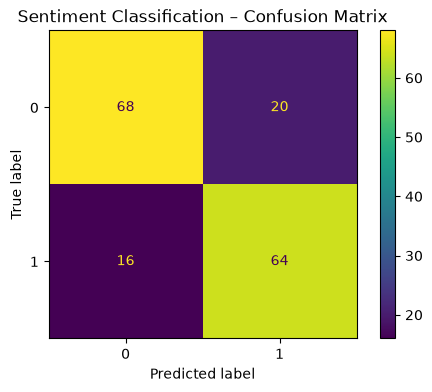

In [5]:
# Our dependent variable.

df['is_acc_321'] = df['class_code'].apply(lambda x: 1 if x == 'ACCT 321' else 0)

y = df['is_acc_321'].values

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_bow, y, test_size=0.3, random_state=42
)

# Train a simple Logistic Regression classifier that uses the Bag-of-Words features (columns)
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

# How well does it do on the training set?
y_train_pred = clf.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_acc}")

# How well does it do on the *test* set?
y_pred = clf.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_acc}")

# Confusion Matrix for test set
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot()
plt.title("Sentiment Classification – Confusion Matrix")
plt.show()



### Step 5: TF-IDF 


In [6]:
# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
X_tfidf = tfidf_vectorizer.fit_transform(df["comment"])

X_tfidf.shape
X_tfidf.toarray()

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(558, 1716))

In [7]:
# Compare the Bag-of-Words and TF-IDF features against each other, showing 
# the first 5 rows and first 10 columns of each
print("Bag-of-Words feature matrix (first 5 rows, 10 columns):")
print(X_bow.toarray()[:5, :10])
print("\nTF-IDF feature matrix (first 5 rows, 10 columns):")
print(X_tfidf.toarray()[:5, :10])

Bag-of-Words feature matrix (first 5 rows, 10 columns):
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]

TF-IDF feature matrix (first 5 rows, 10 columns):
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


Training accuracy: 0.9435897435897436
Test accuracy: 0.7797619047619048


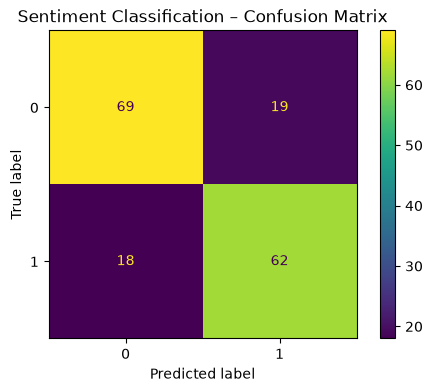

In [8]:
# Do the same train/test split and classification with TF-IDF features
# Use logistical regression again and compare accuracy.
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_tfidf, y, test_size=0.3, random_state=42
)

clf_tfidf = LogisticRegression(max_iter=1000)
clf_tfidf.fit(X_train_t, y_train_t)

# How well does it do on the training set?
y_train_pred = clf_tfidf.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)
print(f"Training accuracy: {train_acc}")

# How well does it do on the *test* set?
y_pred = clf_tfidf.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_acc}")

# Confusion Matrix for test set
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_tfidf.classes_)
disp.plot()
plt.title("Sentiment Classification – Confusion Matrix")
plt.show()


### Step 6: Clustering to explore topics

In [9]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init="auto")
clusters = kmeans.fit_predict(X_tfidf)

df["cluster"] = clusters
df[["comment", "cluster"]]


,comment,cluster
0,homeworks were too complex for the short time ...,2
1,i would recommend a more centralized exam revi...,1
2,more specific examples for written portion of ...,2
3,powerpoints,2
4,the overall helpfulness of the professor and h...,1
...,...,...
565,overall i really enjoyed this course and got a...,1
566,no complaints,2
567,i would lessen the number of data camps after ...,1
569,clarity and conciseness regarding assingmnets,2


In [12]:
terms = tfidf_vectorizer.get_feature_names_out()
centers = kmeans.cluster_centers_

for cluster_id in range(k):
    print(f"\nCluster {cluster_id}")
    center = centers[cluster_id]
    top_idx = center.argsort()[::-1][:20]
    print([terms[i] for i in top_idx])



Cluster 0
['excelfun', 'think', 'assignments', 'certain', 'course', 'helpful', 'beneficial', 'change', 'learning', 'changes', 'dont', 'approach', 'structured', 'sql', 'explanation', 'rounded', 'py', 'straightforward', 'recommendations', 'definitely']

Cluster 1
['good', 'excel', 'course', 'exams', 'practice', 'helpful', 'think', 'class', 'work', 'exam', 'project', 'assignments', 'review', 'homework', 'learning', 'helped', 'better', 'felt', 'doing', 'like']

Cluster 2
['projects', 'time', 'group', 'class', 'learning', 'work', 'great', 'different', 'just', 'think', 'little', 'guidance', 'like', 'maybe', 'liked', 'having', 'datacamp', 'course', 'beneficial', 'helped']

Cluster 3
['instructions', 'assignments', 'clear', 'instructor', 'vague', 'points', 'rubrics', 'times', 'datacamp', 'better', 'helpful', 'office', 'lot', 'multiple', 'hours', 'projects', 'think', 'questions', 'understand', 'easy']

Cluster 4
['class', 'really', 'lot', 'learned', 'professor', 'way', 'garrett', 'like', 'enjo

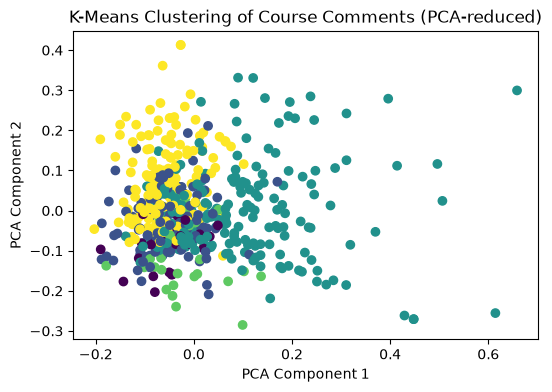

In [13]:
# Visualize clusters using PCA (2D)
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_tfidf.toarray())
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis')
plt.title("K-Means Clustering of Course Comments (PCA-reduced)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()